In [1]:
import nltk
nltk.data.path.append('/tmp/nltk_data')
nltk.download('stopwords', download_dir='/tmp/nltk_data')
nltk.download('wordnet', download_dir='/tmp/nltk_data')
nltk.download('averaged_perceptron_tagger', download_dir='/tmp/nltk_data')

[nltk_data] Downloading package stopwords to /tmp/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /tmp/nltk_data...
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /tmp/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.


True

### Import Neccesary Libraries

In [ ]:
import pandas as pd
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
import torch.optim as optim
from sklearn.preprocessing import LabelEncoder
import torch.nn as nn

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


### Load Dataset

In [4]:
df = pd.read_csv('trustpilot_all_sources_combined.csv')
df.head()

,text,stars,sentiment,source_file
0,I had spent a great deal of time researching t...,1,negative,trustpilot_amazon_1_star_reviews.csv
1,I ordered two items one day. One item was succ...,1,negative,trustpilot_amazon_1_star_reviews.csv
2,By far the absolute worst customer service I'v...,1,negative,trustpilot_amazon_1_star_reviews.csv
3,I purposely placed 2 different orders for a ca...,1,negative,trustpilot_amazon_1_star_reviews.csv
4,I was out for delivery- item placed in drive- ...,1,negative,trustpilot_amazon_1_star_reviews.csv


In [5]:
df.isnull().sum()

text           0
stars          0
sentiment      0
source_file    0
dtype: int64

In [6]:
# Drop Source column
df = df.drop(columns=['source_file'])
df.head()

,text,stars,sentiment
0,I had spent a great deal of time researching t...,1,negative
1,I ordered two items one day. One item was succ...,1,negative
2,By far the absolute worst customer service I'v...,1,negative
3,I purposely placed 2 different orders for a ca...,1,negative
4,I was out for delivery- item placed in drive- ...,1,negative


In [7]:
# neutral_examples = pd.DataFrame({
#     'text': [
#         "It was okay.",
#         "The experience was average.",
#         "Nothing special, but not bad either.",
#         "It met expectations, nothing more.",
#         "Just fine, nothing wrong.",
#         "Decent service, but not impressive.",
#         "Neither good nor bad.",
#         "It's fair, not worth complaining about.",
#         "Satisfactory, but nothing stood out.",
#         "Service was acceptable.",
#         "A normal purchase experience.",
#         "It worked. Nothing extra.",
#         "An average product.",
#     ],
#     'sentiment': ['neutral'] * 13
# })
# df = pd.concat([df, neutral_examples], ignore_index=True)

In [ ]:
# contrast_positive = pd.DataFrame({
#     'text': [
#         "Without this product, I would have been lost. It made everything easier.",
#         "At first I wasn’t sure, but I’m so glad I bought it.",
#         "Started off rough, but it really helped me in the end.",
#         "I doubted it at first, but now I use it every day.",
#         "What began as a mistake turned into a great purchase."
#     ],
#     'sentiment': ['positive'] * 5
# })
# df = pd.concat([df, contrast_positive], ignore_index=True)

In [ ]:
# extra_negative = pd.DataFrame({
#     'text': [
#         "This is bad.",
#         "Worst purchase ever.",
#         "Absolutely terrible product.",
#         "Horrible experience.",
#         "Completely disappointed.",
#         "Terrible service.",
#         "This product sucks.",
#         "Regret buying this.",
#         "It broke after one use.",
#         "Low quality and bad support."
#     ],
#     'sentiment': ['negative'] * 10
# })

# # Append to your main dataset
# df = pd.concat([df, extra_negative], ignore_index=True)


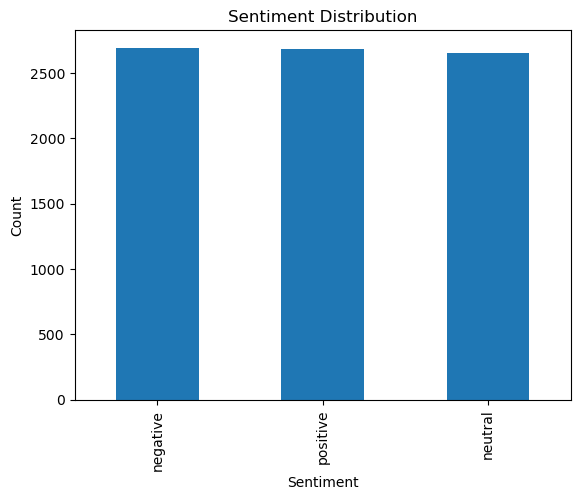

In [10]:
# Plot the distribution of sentiments
import matplotlib.pyplot as plt
df['sentiment'].value_counts().plot(kind='bar')
plt.title('Sentiment Distribution')
plt.xlabel('Sentiment')
plt.ylabel('Count')
plt.show()

In [11]:
from nltk.tokenize import RegexpTokenizer
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Initialize tokenizer, stopwords and lemmatizer once (outside the function for performance)
tokenizer = RegexpTokenizer(r'\w+')  # Only matches words (removes punctuation)
stop_words = set(stopwords.words('english'))  # Common English stopwords
lemmatizer = WordNetLemmatizer()  # Reduces words to their root form

# Preprocessing function to clean text
def preprocess_text(text):
    text = text.lower()  # Convert text to lowercase
    words = tokenizer.tokenize(text)  # Tokenize text into words
    words = [w for w in words if w not in stop_words]  # Remove stopwords like "the", "is", "and"
    words = [lemmatizer.lemmatize(w) for w in words]  # Lemmatize each word (e.g. "running" → "run")
    return ' '.join(words)  # Rejoin cleaned words into a single string

# Apply preprocessing to each row in your DataFrame
df['clean_text'] = df['text'].astype(str).apply(preprocess_text)
df['clean_text'].head()

0    spent great deal time researching right steam ...
1    ordered two item one day one item successfully...
2    far absolute worst customer service ever inter...
3    purposely placed 2 different order capacitor c...
4    delivery item placed drive size could put lett...
Name: clean_text, dtype: object

In [12]:
# Create and apply label encoder
le = LabelEncoder()
df['sentiment_encoded'] = le.fit_transform(df['sentiment'])

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Use bigrams and filter unhelpful words
vectorizer = TfidfVectorizer(
    ngram_range=(1, 3),     # unigrams, bigrams, trigrams
    stop_words='english',     # remove common words
    max_df=0.95,              # ignore terms in >95% of docs, If a term shows up in more than 95% of the documents, it’s probably too generic (think “product” or “service”). Setting max_df=0.95 tells the vectorizer to skip those.
    min_df=2                  # ignore terms that appear in <2 docs, If a term appears in fewer than 2 documents, it may be a typo or too rare to learn from. This drops those super-rare tokens.
)

# Fit and transform the clean text
X_vectorized = vectorizer.fit_transform(df['clean_text']).toarray()

# Target variable (sentiment encoded)
y = df['sentiment_encoded']

In [14]:
from sklearn.model_selection import train_test_split
# Split into 80% training and 20% test
X_train, X_test, y_train, y_test = train_test_split(X_vectorized, y, test_size=0.2, random_state=42)

# Naive_Bayes Model

In [15]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)

MultinomialNB()

In [16]:
from sklearn.metrics import classification_report, accuracy_score

y_pred = nb_model.predict(X_test)

print(f"Naive Bayes Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(classification_report(y_test, y_pred, target_names=le.classes_))

Naive Bayes Accuracy: 0.7746
              precision    recall  f1-score   support

    negative       0.71      0.92      0.80       545
     neutral       0.81      0.66      0.73       540
    positive       0.84      0.75      0.79       521

    accuracy                           0.77      1606
   macro avg       0.79      0.77      0.77      1606
weighted avg       0.79      0.77      0.77      1606



# Neural Network Model

In [17]:
# Create PyTorch Dataset
class SentimentDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y.values, dtype=torch.long)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_dataset = SentimentDataset(X_train, y_train)
test_dataset = SentimentDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128)

In [18]:
# Define Neural Network
class SentimentNet(nn.Module):
    def __init__(self, input_size, num_classes):
        super(SentimentNet, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(input_size, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.model(x)

model_NN = SentimentNet(input_size=X_train.shape[1], num_classes=3).to(device)

In [19]:
# Train the Model
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_NN.parameters(), lr=0.001)
loss_history = []

for epoch in range(50):
    model_NN.train()
    total_loss = 0

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()
        output = model_NN(X_batch)
        loss = criterion(output, y_batch)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    loss_history.append(total_loss)

    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1}, Loss: {total_loss:.5f}")


Epoch 5, Loss: 1.11181
Epoch 10, Loss: 0.36062
Epoch 15, Loss: 0.21225
Epoch 20, Loss: 0.24427
Epoch 25, Loss: 0.24838
Epoch 30, Loss: 0.21200
Epoch 35, Loss: 0.19492
Epoch 40, Loss: 0.21279
Epoch 45, Loss: 0.18959
Epoch 50, Loss: 0.15098


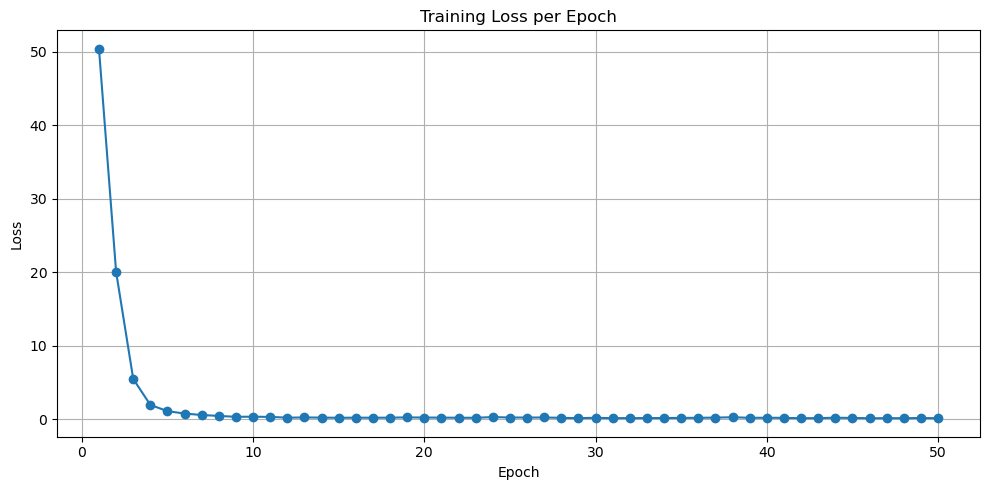

In [20]:
# Plot loss curve after training
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(loss_history)+1), loss_history, marker='o')
plt.title("Training Loss per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.tight_layout()
plt.show()

In [21]:
# Evaluate the Model
model_NN.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)
        outputs = model_NN(X_batch)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y_batch.cpu().numpy())

print(classification_report(all_labels, all_preds, target_names=le.classes_))

              precision    recall  f1-score   support

    negative       0.78      0.80      0.79       545
     neutral       0.69      0.75      0.72       540
    positive       0.82      0.72      0.77       521

    accuracy                           0.76      1606
   macro avg       0.76      0.76      0.76      1606
weighted avg       0.76      0.76      0.76      1606



### Test the model with new examples

In [22]:
def predict_sentiment(text):
    sample_clean = [preprocess_text(text)]
    X_sample = vectorizer.transform(sample_clean)
    X_tensor = torch.tensor(X_sample.toarray(), dtype=torch.float32).to(device)
    model_NN.eval()
    with torch.no_grad():
        output = model_NN(X_tensor)
        _, prediction = torch.max(output, dim=1)
    return le.inverse_transform(prediction.cpu().numpy())[0]

# Example
print(predict_sentiment("The delivery was too slow, but the product is okay."))

neutral


# Logistic Regression CV Model

In [ ]:
from sklearn.linear_model import LogisticRegressionCV

model = LogisticRegressionCV(
    cv=3, #It splits your training data into 3 parts, trains on 2 and tests on 1, rotating them.
    max_iter=300,
    scoring='f1_macro' # Macro means it treats each class equally, even if data is imbalanced.
)
model.fit(X_train, y_train)

LogisticRegressionCV(cv=3, max_iter=300, scoring='f1_macro')

In [24]:
from sklearn.metrics import classification_report, accuracy_score

# Predict on test set
y_pred = model.predict(X_test)

print(f"Logistic_Regression_CV Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(classification_report(y_test, y_pred, target_names=le.classes_))

Logistic_Regression_CV Accuracy: 0.7771
              precision    recall  f1-score   support

    negative       0.78      0.83      0.80       545
     neutral       0.75      0.71      0.73       540
    positive       0.80      0.79      0.80       521

    accuracy                           0.78      1606
   macro avg       0.78      0.78      0.78      1606
weighted avg       0.78      0.78      0.78      1606



# SVC Model

In [25]:
from sklearn.svm import LinearSVC

svc_model = LinearSVC(max_iter=1000)
svc_model.fit(X_train, y_train)

LinearSVC()

In [26]:
# Model evaluation
y_pred_svc = svc_model.predict(X_test)

print(f"SVC Accuracy: {accuracy_score(y_test, y_pred_svc):.4f}")
print(classification_report(y_test, y_pred_svc, target_names=le.classes_))

SVC Accuracy: 0.7740
              precision    recall  f1-score   support

    negative       0.78      0.82      0.80       545
     neutral       0.75      0.69      0.72       540
    positive       0.79      0.81      0.80       521

    accuracy                           0.77      1606
   macro avg       0.77      0.77      0.77      1606
weighted avg       0.77      0.77      0.77      1606



### Save the Model (Logistic Regression CV)

In [27]:
# Save model and vectorizer
import joblib

joblib.dump(model, "logistic_model.joblib")
joblib.dump(vectorizer, "tfidf_vectorizer.joblib")

['tfidf_vectorizer.joblib']